<a href="https://colab.research.google.com/github/awyukt25/SCT_ML_1/blob/main/House_Price_Prediction_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction using Linear Regression

**Task (SkillCraft Technology):** Implement a linear regression model to predict the prices of houses based on their square footage and the number of bedrooms and bathrooms.

**Dataset:** Kaggle *House Prices - Advanced Regression Techniques* (`train.csv`, `test.csv`)

**Inputs:** square footage (`GrLivArea`), bedrooms (`BedroomAbvGr`), bathrooms (`TotalBaths`, built from full, half and basement baths)  
**Target:** `SalePrice`

**What this notebook covers**
- Building one bathroom feature that counts half and basement baths properly
- Checking how the inputs overlap (correlation heatmap and VIF)
- Finding outlier houses and measuring how much they affect the model
- Comparing the model against a "predict the average" baseline
- Evaluating with a train/test split and 5-fold cross-validation
- Reading coefficients in dollars, ranking inputs, and checking p-values
- Testing whether predicting log(price) fits better
- A `predict_price()` function for any new house, and predictions on Kaggle's `test.csv`

**How to run:** upload `train.csv` and `test.csv` to Colab (folder icon, then upload), then choose **Runtime > Run all**.

**Tech:** Python, Pandas, NumPy, Scikit-learn, Statsmodels, Matplotlib, Seaborn

## 1. Imports

In [23]:
# IMPORTS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 2. Load the data

In [24]:
# LOAD THE DATA
# Upload train.csv (and test.csv, used only in the last section) to Colab.

TRAIN_PATH = '/content/train.csv'
TEST_PATH = '/content/test.csv'

train = pd.read_csv(TRAIN_PATH)
print("Train shape:", train.shape)
train.head()

Train shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Build the three inputs

In [25]:
# BUILD THE THREE INPUTS
# Square footage : GrLivArea (above-ground living area, sq ft)
# Bedrooms       : BedroomAbvGr
# Bathrooms      : the dataset splits baths into four columns. A half bath
#                  is not a full bath, so it counts as 0.5. Basement baths
#                  are real baths too, so they are included.

df = train.copy()
df['TotalBaths'] = (df['FullBath'] + 0.5 * df['HalfBath']
                    + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])

FEATURES = ['GrLivArea', 'BedroomAbvGr', 'TotalBaths']
TARGET = 'SalePrice'

data = df[FEATURES + [TARGET]].copy()
data.describe().round(2)

,GrLivArea,BedroomAbvGr,TotalBaths,SalePrice
count,1460.00,1460.00,1460.00,1460.0
mean,1515.46,2.87,2.21,180921.2
std,525.48,0.82,0.79,79442.5
min,334.00,0.00,1.00,34900.0
25%,1129.50,2.00,2.00,129975.0
50%,1464.00,3.00,2.00,163000.0
75%,1776.75,3.00,2.50,214000.0
max,5642.00,8.00,6.00,755000.0


## 4. Data quality check

In [26]:
# DATA QUALITY CHECK

print("Missing values:")
print(data.isnull().sum())
print("\nDuplicate rows:", data.duplicated().sum())
print("\nBedroom counts:")
print(data['BedroomAbvGr'].value_counts().sort_index())

Missing values:
GrLivArea       0
BedroomAbvGr    0
TotalBaths      0
SalePrice       0
dtype: int64

Duplicate rows: 4

Bedroom counts:
BedroomAbvGr
0      6
1     50
2    358
3    804
4    213
5     21
6      7
8      1
Name: count, dtype: int64


## 5. Explore how each input relates to price

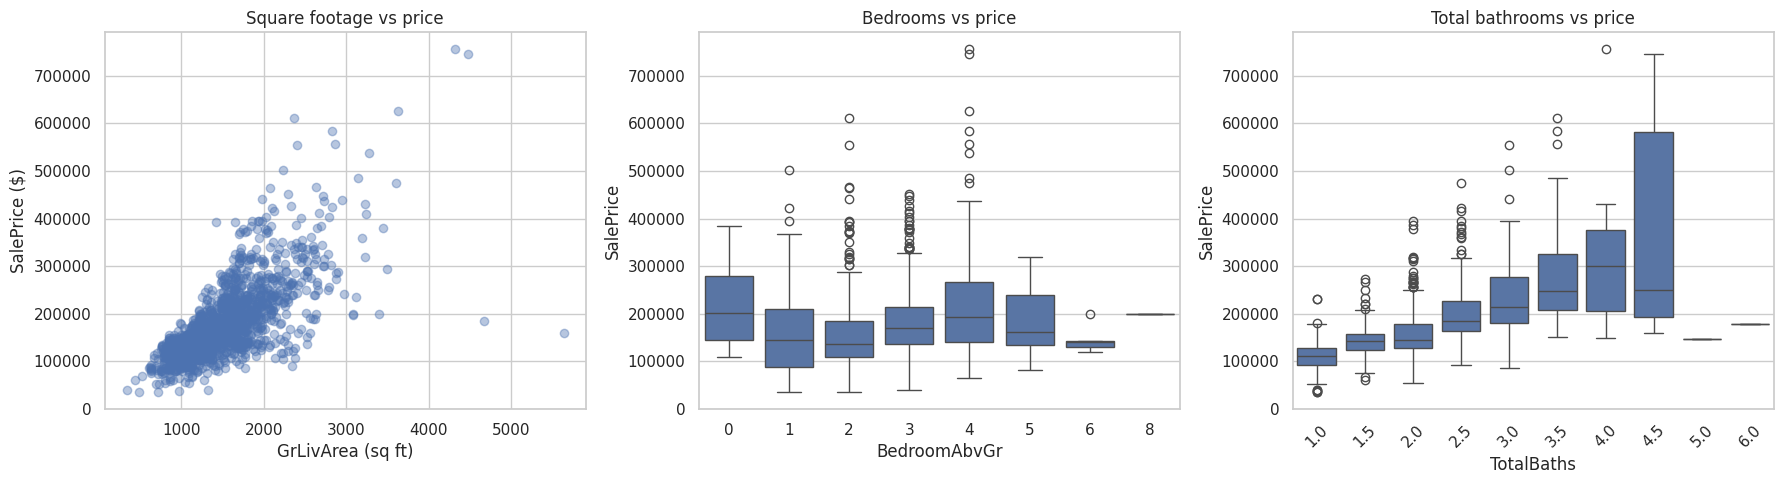

In [27]:
# EXPLORE: HOW DOES EACH INPUT RELATE TO PRICE?

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(data['GrLivArea'], data[TARGET], alpha=0.4)
axes[0].set_title("Square footage vs price")
axes[0].set_xlabel("GrLivArea (sq ft)")
axes[0].set_ylabel("SalePrice ($)")

sns.boxplot(x=data['BedroomAbvGr'], y=data[TARGET], ax=axes[1])
axes[1].set_title("Bedrooms vs price")

sns.boxplot(x=data['TotalBaths'], y=data[TARGET], ax=axes[2])
axes[2].set_title("Total bathrooms vs price")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 6. Do the inputs overlap with each other?

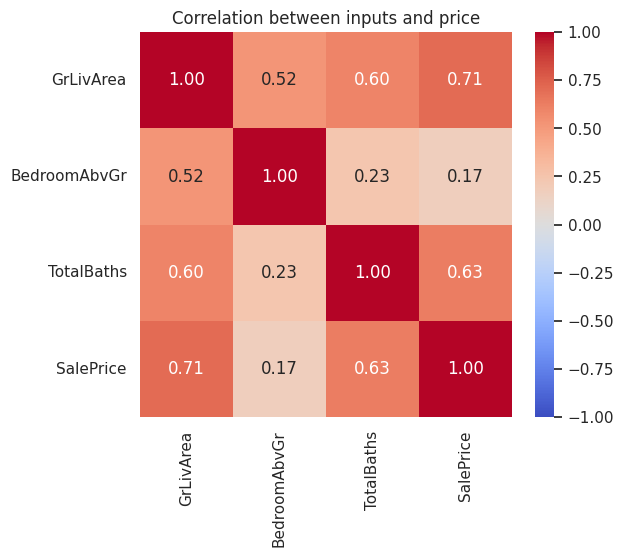

        Feature   VIF
0     GrLivArea  2.03
1  BedroomAbvGr  1.39
2    TotalBaths  1.57

Rule of thumb: VIF below 5 is fine, above 10 is a real problem.


In [28]:
# DO THE INPUTS OVERLAP WITH EACH OTHER?
# Bigger houses tend to have more bedrooms AND more baths. When inputs move
# together like this (multicollinearity), individual coefficients become
# harder to read. The correlation heatmap and VIF quantify this.

plt.figure(figsize=(6, 5))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between inputs and price")
plt.show()

X_vif = sm.add_constant(data[FEATURES])
vif = pd.DataFrame({
    'Feature': FEATURES,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(FEATURES))]
})
print(vif.round(2))
print("\nRule of thumb: VIF below 5 is fine, above 10 is a real problem.")

## 7. Outliers

Outlier houses found: 2
      GrLivArea  BedroomAbvGr  TotalBaths  SalePrice
523        4676             3         4.5     184750
1298       5642             3         4.5     160000


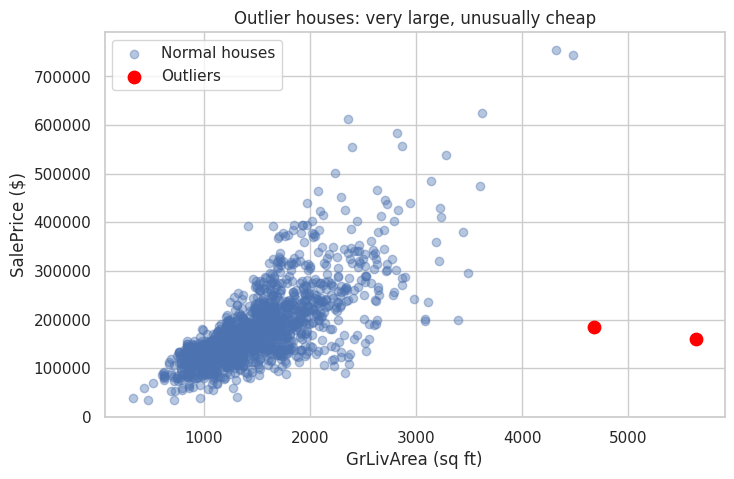

In [29]:
# OUTLIERS
# This dataset is known for a few very large houses that sold cheaply.
# A straight line gets pulled toward them. Flag them and look.

outlier_mask = (data['GrLivArea'] > 4000) & (data[TARGET] < 300000)
outliers = data[outlier_mask]
clean = data[~outlier_mask].copy()

print("Outlier houses found:", len(outliers))
print(outliers)

plt.figure(figsize=(8, 5))
plt.scatter(clean['GrLivArea'], clean[TARGET], alpha=0.4, label="Normal houses")
plt.scatter(outliers['GrLivArea'], outliers[TARGET], color="red", s=80, label="Outliers")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.title("Outlier houses: very large, unusually cheap")
plt.legend()
plt.show()

## 8. Train / test split

In [30]:
# TRAIN / TEST SPLIT (on the cleaned data)

X = clean[FEATURES]
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7
)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 1166
Testing rows : 292


## 9. Helper: evaluate any model the same way

In [31]:
# HELPER: EVALUATE ANY MODEL THE SAME WAY

def evaluate(model, X_tr, y_tr, X_te, y_te, label):
    rows = {}
    for name, X_, y_ in [('Train', X_tr, y_tr), ('Test', X_te, y_te)]:
        pred = model.predict(X_)
        rows[name] = {
            'MAE': mean_absolute_error(y_, pred),
            'RMSE': np.sqrt(mean_squared_error(y_, pred)),
            'R2': r2_score(y_, pred)
        }
    table = pd.DataFrame(rows).T.round(3)
    print(f"--- {label} ---")
    print(table)
    print()
    return table

## 10. Baseline: always predict the average price

In [32]:
# BASELINE: ALWAYS PREDICT THE AVERAGE PRICE
# Any real model has to beat this, otherwise it has learned nothing.

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_results = evaluate(baseline, X_train, y_train, X_test, y_test, "Baseline (average price)")

--- Baseline (average price) ---
             MAE       RMSE     R2
Train  55960.002  77276.505  0.000
Test   61962.571  87739.783 -0.008



## 11. The linear regression model (as a Pipeline)

In [33]:
# THE LINEAR REGRESSION MODEL (as a Pipeline)
# StandardScaler does not change the predictions of a linear model, but it
# lets us compare how strongly each input matters (Section 14).

lin_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
lin_pipe.fit(X_train, y_train)
lin_results = evaluate(lin_pipe, X_train, y_train, X_test, y_test, "Linear regression")

--- Linear regression ---
             MAE       RMSE     R2
Train  32595.958  45358.004  0.655
Test   36618.390  49921.302  0.674



## 12. 5-fold cross-validation

In [34]:
# 5-FOLD CROSS-VALIDATION
# One train/test split can be lucky or unlucky. This repeats the whole
# process on 5 different splits of the training data.

cv = KFold(n_splits=5, shuffle=True, random_state=7)
cv_r2 = cross_val_score(lin_pipe, X_train, y_train, cv=cv, scoring='r2')
cv_rmse = -cross_val_score(lin_pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')

print("R2 per fold  :", cv_r2.round(3))
print("Mean R2      :", round(cv_r2.mean(), 3), "+/-", round(cv_r2.std(), 3))
print("RMSE per fold:", cv_rmse.round(0))
print("Mean RMSE    : $", round(cv_rmse.mean(), 0))

R2 per fold  : [0.644 0.573 0.684 0.677 0.632]
Mean R2      : 0.642 +/- 0.04
RMSE per fold: [42142. 44682. 48195. 46799. 46168.]
Mean RMSE    : $ 45597.0


## 13. Coefficients in real units (dollars per unit)

In [35]:
# COEFFICIENTS IN REAL UNITS (dollars per unit)
# The pipeline learned coefficients on scaled data. Dividing by each
# feature's scale converts them back into dollars per sq ft, per bedroom,
# and per bathroom.

scaler = lin_pipe.named_steps['scaler']
model = lin_pipe.named_steps['model']

raw_coefs = model.coef_ / scaler.scale_
raw_intercept = model.intercept_ - np.sum(raw_coefs * scaler.mean_)

print(f"Intercept: ${raw_intercept:,.0f}")
for name, coef in zip(FEATURES, raw_coefs):
    print(f"{name:14s}: ${coef:,.2f} per unit")

Intercept: $33,292
GrLivArea     : $114.55 per unit
BedroomAbvGr  : $-29,065.04 per unit
TotalBaths    : $26,312.39 per unit


## 14. Which input matters most?

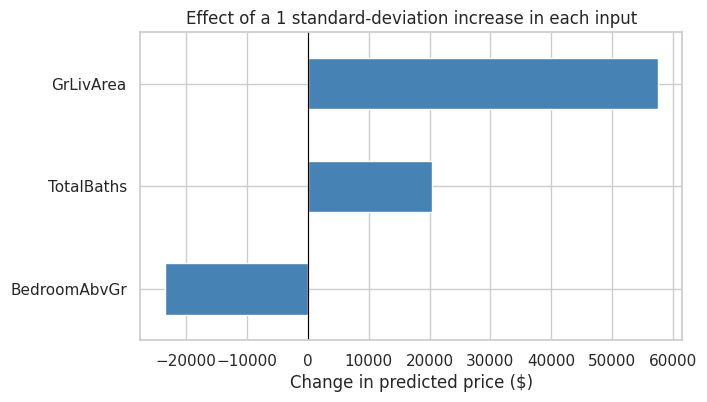

In [36]:
# WHICH INPUT MATTERS MOST?
# Raw coefficients cannot be compared (a sq ft and a bedroom are different
# units). Standardized coefficients can: each shows the price change, in
# dollars, for a one standard-deviation increase in that input.

std_coefs = pd.Series(model.coef_, index=FEATURES).sort_values()

plt.figure(figsize=(7, 4))
std_coefs.plot(kind='barh', color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Effect of a 1 standard-deviation increase in each input")
plt.xlabel("Change in predicted price ($)")
plt.show()

## 15. Statistical significance (statsmodels)

In [37]:
# STATISTICAL SIGNIFICANCE (statsmodels)
# p-values and confidence intervals tell you whether each input has a real
# effect, or whether its coefficient could just be noise. Read the bedroom
# row carefully: with square footage already in the model, its coefficient
# can be small or even negative.

X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.655
Model:                            OLS   Adj. R-squared:                  0.655
Method:                 Least Squares   F-statistic:                     736.9
Date:                Mon, 28 Sep 2026   Prob (F-statistic):          2.91e-268
Time:                        05:02:26   Log-Likelihood:                -14157.
No. Observations:                1166   AIC:                         2.832e+04
Df Residuals:                    1162   BIC:                         2.834e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         3.329e+04   5627.919      5.916   

## 16. Does predicting log(price) fit better?

In [38]:
# DOES PREDICTING log(PRICE) FIT BETTER?
# Prices are right-skewed, so errors tend to grow with price. Fitting on the
# log of price often helps. TransformedTargetRegressor handles the
# conversion back to dollars automatically, so results stay comparable.

log_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])
log_pipe.fit(X_train, y_train)
log_results = evaluate(log_pipe, X_train, y_train, X_test, y_test, "Linear regression on log(price)")

--- Linear regression on log(price) ---
             MAE       RMSE     R2
Train  31420.722  45541.269  0.653
Test   32659.505  47288.218  0.707



## 17. How much do the outliers matter?

In [39]:
# HOW MUCH DO THE OUTLIERS MATTER?
# Retrain the same model with the outlier houses put back into the training
# data, then test on the SAME clean test set, so the comparison is fair.

X_with_out = pd.concat([X_train, outliers[FEATURES]])
y_with_out = pd.concat([y_train, outliers[TARGET]])

pipe_with_outliers = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
pipe_with_outliers.fit(X_with_out, y_with_out)
out_results = evaluate(pipe_with_outliers, X_with_out, y_with_out, X_test, y_test,
                       "Linear regression trained WITH outliers")

--- Linear regression trained WITH outliers ---
             MAE       RMSE     R2
Train  32868.684  49106.179  0.596
Test   36148.633  50559.061  0.665



## 18. Compare everything on the same test set

In [40]:
# COMPARE EVERYTHING ON THE SAME TEST SET

comparison = pd.DataFrame({
    'Baseline (average)': baseline_results.loc['Test'],
    'Linear (outliers removed)': lin_results.loc['Test'],
    'Linear (outliers kept)': out_results.loc['Test'],
    'Linear on log(price)': log_results.loc['Test'],
}).T
print(comparison)

                                 MAE       RMSE     R2
Baseline (average)         61962.571  87739.783 -0.008
Linear (outliers removed)  36618.390  49921.302  0.674
Linear (outliers kept)     36148.633  50559.061  0.665
Linear on log(price)       32659.505  47288.218  0.707


## 19. Diagnostic plots for the main model

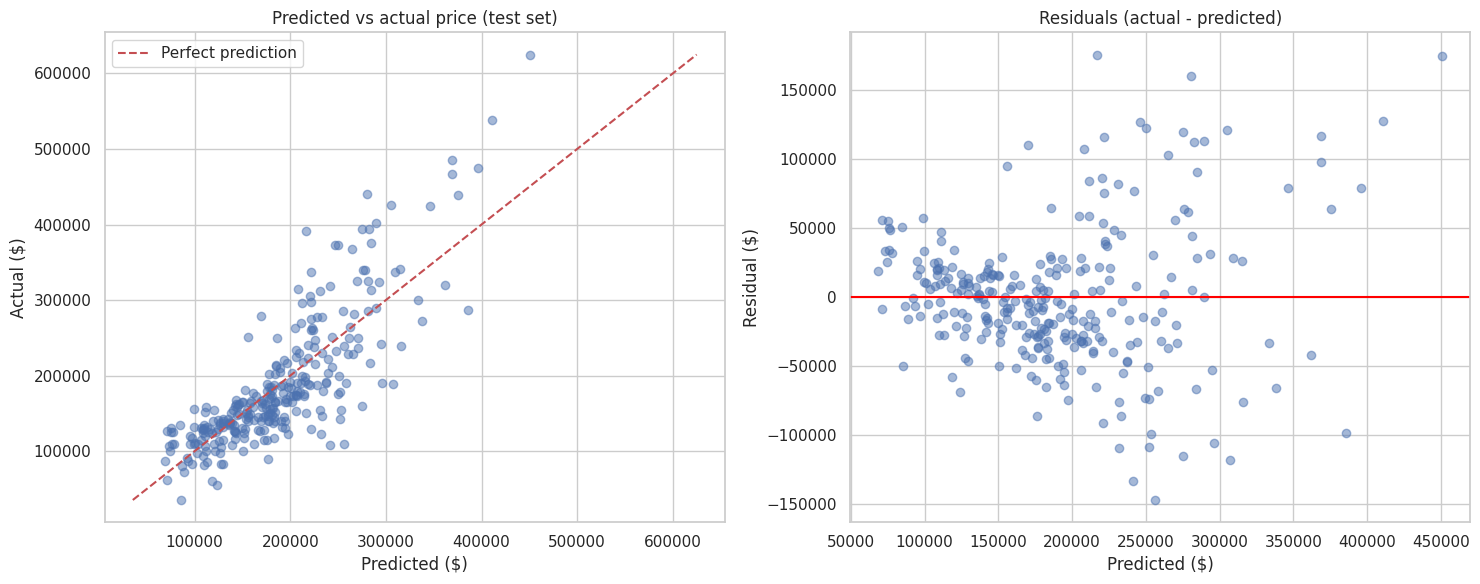

In [41]:
# DIAGNOSTIC PLOTS FOR THE MAIN MODEL

test_pred = lin_pipe.predict(X_test)
residuals = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(test_pred, y_test, alpha=0.5)
lims = [min(test_pred.min(), y_test.min()), max(test_pred.max(), y_test.max())]
axes[0].plot(lims, lims, 'r--', label="Perfect prediction")
axes[0].set_title("Predicted vs actual price (test set)")
axes[0].set_xlabel("Predicted ($)")
axes[0].set_ylabel("Actual ($)")
axes[0].legend()

axes[1].scatter(test_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red')
axes[1].set_title("Residuals (actual - predicted)")
axes[1].set_xlabel("Predicted ($)")
axes[1].set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()

## 20. Actual vs predicted table

In [42]:
# ACTUAL vs PREDICTED TABLE

results_table = pd.DataFrame({
    'Actual': y_test,
    'Predicted': test_pred.round(0),
    'Error ($)': (y_test - test_pred).round(0),
    'Error (%)': ((y_test - test_pred) / y_test * 100).round(1)
})
results_table.head(10)

,Actual,Predicted,Error ($),Error (%)
409,339750,276228.0,63522.0,18.7
369,162000,146149.0,15851.0,9.8
709,109900,75964.0,33936.0,30.9
755,172500,180383.0,-7883.0,-4.6
146,105000,128019.0,-23019.0,-21.9
275,205000,189203.0,15797.0,7.7
955,145000,193948.0,-48948.0,-33.8
1292,107500,241372.0,-133872.0,-124.5
450,110000,94605.0,15395.0,14.0
1394,246578,225926.0,20652.0,8.4


## 21. Predict the price of any house

In [43]:
# PREDICT THE PRICE OF ANY HOUSE
# This is the practical use of the model: give it a house, get a price.

train_min = X_train.min()
train_max = X_train.max()

def predict_price(sqft, bedrooms, bathrooms):
    house = pd.DataFrame([[sqft, bedrooms, bathrooms]], columns=FEATURES)

    # Warn if the house is outside what the model was trained on
    for col, value in zip(FEATURES, [sqft, bedrooms, bathrooms]):
        if value < train_min[col] or value > train_max[col]:
            print(f"Warning: {col}={value} is outside the training range "
                  f"({train_min[col]} to {train_max[col]}). Treat this prediction with caution.")

    price = lin_pipe.predict(house)[0]
    return round(price, 0)

print("1,500 sq ft, 3 bed, 2 bath :", f"${predict_price(1500, 3, 2):,.0f}")
print("2,400 sq ft, 4 bed, 3 bath :", f"${predict_price(2400, 4, 3):,.0f}")
print("900 sq ft, 2 bed, 1 bath   :", f"${predict_price(900, 2, 1):,.0f}")

1,500 sq ft, 3 bed, 2 bath : $170,549
2,400 sq ft, 4 bed, 3 bath : $270,892
900 sq ft, 2 bed, 1 bath   : $104,571


## 22. Optional: predict on Kaggle's test.csv and save a submission file

In [44]:
# OPTIONAL: PREDICT ON KAGGLE'S test.csv AND SAVE A SUBMISSION FILE
# test.csv has no SalePrice column, so these are real predictions, not a
# score. Retrain on all cleaned data first, then fill any gaps in test.csv.

test = pd.read_csv(TEST_PATH)

for col in ['BsmtFullBath', 'BsmtHalfBath']:
    test[col] = test[col].fillna(0)   # missing basement bath = no basement bath

test['TotalBaths'] = (test['FullBath'] + 0.5 * test['HalfBath']
                      + test['BsmtFullBath'] + 0.5 * test['BsmtHalfBath'])

X_kaggle = test[FEATURES].copy()
for col in ['GrLivArea', 'BedroomAbvGr']:
    X_kaggle[col] = X_kaggle[col].fillna(X[col].median())

final_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
final_model.fit(X, y)

submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': final_model.predict(X_kaggle).round(2)
})
submission.to_csv('submission.csv', index=False)
print("Saved submission.csv with", len(submission), "predictions")
submission.head()

Saved submission.csv with 1459 predictions


,Id,SalePrice
0,1461,101601.74
1,1462,136817.14
2,1463,198829.42
3,1464,195978.51
4,1465,173193.09


## Conclusion

- Used the three inputs the task specifies, and built one bathroom  
  feature that counts half and basement baths properly  
- Checked input overlap (correlation, VIF) before trusting coefficients  
- Found outlier houses and measured how much they change the model  
- Compared the model to a baseline, using train/test AND 5-fold CV  
- Read coefficients in dollars, ranked inputs with standardized  
  coefficients, and checked significance with p-values  
- Tested a log(price) version  
- Wrote predict_price() so the model can be used on any new house  
  
Be honest about the limit: three inputs cannot capture location, quality  
or condition, so a large share of price variation is left unexplained.

*(Replace this with your own summary and your actual results.)*